# Libraries & Load Data

In [ ]:
!pip -q install "kagglehub[pandas-datasets]" pandas "dask[complete]" psutil matplotlib pyarrow

In [ ]:
import numpy as np
import pandas as pd
import dask.dataframe as dd
import kagglehub
import psutil
import time
import gc
import matplotlib.pyplot as plt
from pathlib import Path
import threading


In [ ]:

dataset_dir = kagglehub.dataset_download(
    "forgemaster/steam-reviews-dataset"
)

DATA_DIR = Path(dataset_dir)
csv_files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(csv_files))
print("Total size (GB):", round(
    sum(f.stat().st_size for f in csv_files) / 1e9, 2
))

Using Colab cache for faster access to the 'steam-reviews-dataset' dataset.
Number of CSV files: 11
Total size (GB): 5.32


#Traditional Pandas

In [ ]:
process = psutil.Process()


#Added Later
def monitor_memory(process, stop_event, samples):
    while not stop_event.is_set():
        samples.append(process.memory_info().rss / 1e9)
        time.sleep(0.05)

def start_monitor():
    stop_event = threading.Event()
    samples = [process.memory_info().rss / 1e9]

    thread = threading.Thread(
        target=monitor_memory,
        args=(process, stop_event, samples),
        daemon=True
    )
    thread.start()
    return stop_event, thread, samples

def stop_monitor(monitor):
    stop_event, thread, samples = monitor
    stop_event.set()
    thread.join()
    samples.append(process.memory_info().rss / 1e9)
    return max(samples)



pandas_memory_before = process.memory_info().rss / 1e9
start = time.time()

#Added Later

monitor = start_monitor()
try:
    dfs = [pd.read_csv(file) for file in csv_files]
    df_full = pd.concat(dfs, ignore_index=True)

    pandas_time = time.time() - start
    pandas_memory = process.memory_info().rss / 1e9
    pandas_memory = stop_monitor(monitor)

    print("Loading succeeded")
    print("Shape:", df_full.shape)
    print(dfs[0].columns.tolist())

    print("Execution time:", round(pandas_time, 2), "seconds")
    print("Process memory before:", round(pandas_memory_before, 2), "GB")
    print("Process memory after:", round(pandas_memory, 2), "GB")

    del dfs
    del df_full
    gc.collect()

except MemoryError:
    pandas_time = time.time() - start
    # pandas_memory = process.memory_info().rss / 1e9
    pandas_memory = stop_monitor(monitor)
    print("MemoryError: Not enough memory to load the dataset.")
    print("Execution time:", round(pandas_time, 2), "seconds")
    print("Process memory before:", round(pandas_memory_before, 2), "GB")
    print("Maximum traditional pandas memory :", round(pandas_memory, 2), "GB")

Loading succeeded
Shape: (15437471, 13)
['steamid', 'appid', 'voted_up', 'votes_up', 'votes_funny', 'weighted_vote_score', 'playtime_forever', 'playtime_at_review', 'num_games_owned', 'num_reviews', 'review', 'unix_timestamp_created', 'unix_timestamp_updated']
Execution time: 109.21 seconds
Process memory before: 3.76 GB
Process memory after: 8.39 GB


#Pandas Chunking

In [ ]:
CHUNK_SIZE = 100_000

total_sum = None
total_count = None
total_rows = 0
start = time.time()
chunk_memory_before = process.memory_info().rss / 1e9
# max_memory = memory_before
exclude=["steamid", "appid"]
#Added Later
monitor = start_monitor()
for file in csv_files:
    for chunk in pd.read_csv(file, chunksize=CHUNK_SIZE):
        numeric = chunk.select_dtypes(include="number")
        numeric = numeric.drop(columns=exclude,errors="ignore")

        if total_sum is None:
            total_sum = numeric.sum()
            total_count = numeric.count()
        else:
            total_sum = total_sum.add(numeric.sum(), fill_value=0)
            total_count = total_count.add(numeric.count(), fill_value=0)

        total_rows += len(chunk)
        # max_memory = max(
        #     max_memory,
        #     process.memory_info().rss / 1e9
        # )
#Added Later
chunk_memory = stop_monitor(monitor)
chunk_time = time.time() - start

means = total_sum / total_count

print("Total rows processed:", total_rows)
print("Execution time:", round(chunk_time, 2), "seconds")
print("Process memory before:", round(chunk_memory_before, 2), "GB")
print("Maximum pandas chunking memory:", round(chunk_memory, 2), "GB")
print("\nMean of numeric columns:")
print(means)

Total rows processed: 15437471
Execution time: 115.93 seconds
Process memory before: 4.55 GB
Maximum pandas chunking memory: 4.55 GB

Mean of numeric columns:
votes_up                  2.379840e+00
votes_funny               1.616449e+05
playtime_forever          1.532429e+04
playtime_at_review        8.100505e+03
num_games_owned           1.985849e+02
num_reviews               1.718521e+01
unix_timestamp_created    1.526390e+09
unix_timestamp_updated    1.530168e+09
dtype: float64


#Dask

In [ ]:
start = time.time()
dask_memory_before = process.memory_info().rss / 1e9
#Added Later
monitor = start_monitor()
ddf = dd.read_csv(
    str(DATA_DIR / "*.csv"),
    blocksize=None,
    assume_missing=True
)

print("Number of partitions:", ddf.npartitions)
print("Columns:", list(ddf.columns))

# Lazy Evaluation: Dask builds the tasks before executing them

numeric_columns = ddf.select_dtypes(include="number").columns.tolist()
numeric_columns = [col for col in numeric_columns if col not in exclude]

sum_task = ddf[numeric_columns].sum()
count_task = ddf[numeric_columns].count()
rows_task = ddf.shape[0]

# Optimize and compute
sum_task, count_task, rows_task = dd.compute(
    sum_task, count_task, rows_task
)

dask_time = time.time() - start
# dask_memory = process.memory_info().rss / 1e9
#Added Later
dask_memory = stop_monitor(monitor)
print("Total rows:", rows_task)
print("Execution time:", round(dask_time, 2), "seconds")
print("Process memory before:", round(dask_memory_before, 2), "GB")
print("MaximumProcess Dask memory:", round(dask_memory, 2), "GB")
print("\nMean of numeric columns:")
print(sum_task / count_task)

Number of partitions: 11
Columns: ['steamid', 'appid', 'voted_up', 'votes_up', 'votes_funny', 'weighted_vote_score', 'playtime_forever', 'playtime_at_review', 'num_games_owned', 'num_reviews', 'review', 'unix_timestamp_created', 'unix_timestamp_updated']
Total rows: 15437471
Execution time: 226.83 seconds
Process memory before: 4.24 GB
MaximumProcess Dask memory: 10.84 GB

Mean of numeric columns:
votes_up                  2.379840e+00
votes_funny               1.616449e+05
weighted_vote_score       1.964402e-01
playtime_forever          1.532429e+04
playtime_at_review        8.100505e+03
num_games_owned           1.985849e+02
num_reviews               1.718521e+01
unix_timestamp_created    1.526390e+09
unix_timestamp_updated    1.530168e+09
dtype: float64


#Comparaison

Measured Performance Benchmark:
         Method  Max RAM (GB)  Execution Time (seconds)
Standard Pandas          8.39                    109.21
Pandas Chunking          4.55                    115.93
 Dask DataFrame         10.84                    226.83


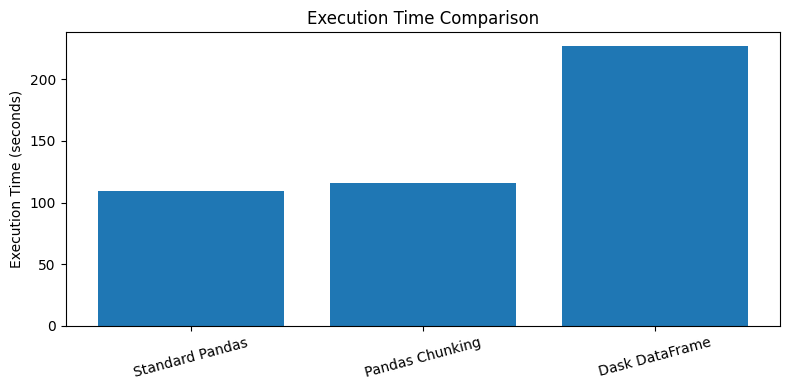

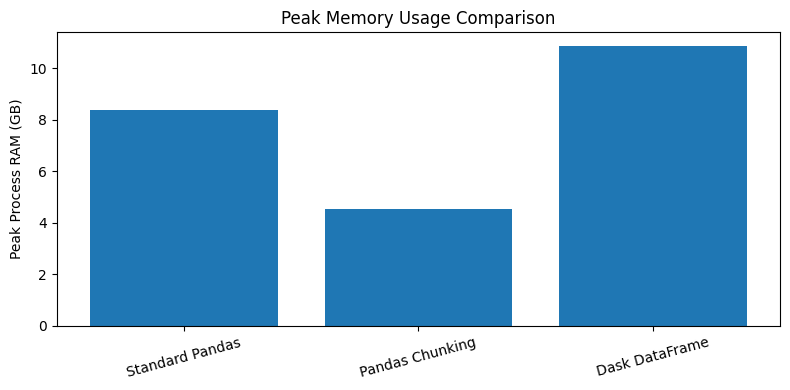

In [ ]:

# Performance Benchmark

methods = ["Standard Pandas", "Pandas Chunking", "Dask DataFrame"]

times = [
    pandas_time if "pandas_time" in globals() else float("nan"),
    chunk_time,
    dask_time
]

memories = [
    pandas_memory if "pandas_memory" in globals() else float("nan"),
    chunk_memory,
    dask_memory
]

results = pd.DataFrame({
    "Method": methods,
    "Max RAM (GB)": memories,
    "Execution Time (seconds)": times
})

print("Measured Performance Benchmark:")
print(results.round(2).to_string(index=False))

# Execution Time Comparison
plt.figure(figsize=(8, 4))
plt.bar(methods, times)
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Peak Memory Comparison
plt.figure(figsize=(8, 4))
plt.bar(methods, memories)
plt.ylabel("Peak Process RAM (GB)")
plt.title("Peak Memory Usage Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

